# Analysis on the cleaned dataset

In [49]:
import pandas as pd
import numpy as np
travel_data = pd.read_csv("cleanTravelData.csv")
travel_data.head(6)
# print(travel_data.anticipatedcommission_total.max())
# comm_bins = np.linspace(travel_data.anticipatedcommission_total.min(), travel_data.anticipatedcommission_total.max(), 50)
# travel_data['comm_binned'] = pd.cut(travel_data.anticipatedcommission_total, comm_bins)

,clientid,bkgref,Trip ID,destination,destinationcountry,destinationcountry2,category,date_of_trip_from,date_of_trip_to,year,month,bkgsource,landsalecost_total,anticipatedcommission_total,groupsize,profit_margin
0,138,B12-28876,150,Alaska Fishing,Alaska,Alaska,FW,7/14/2012,7/22/2012,2012,7,Company referral,4550.0,455.00,1,0.100000
1,138,B15-39172,238,H2O Bahamas,Bahamas,Bahamas,SW,10/30/2015,11/3/2015,2015,10,Repeat Client,7260.0,1012.52,4,0.139466
2,138,B18-49058,211,Deep Water Cay,Bahamas,Bahamas,SW,2/15/2019,2/19/2019,2019,2,Repeat Client,14598.5,2300.00,4,0.157550
3,138,B19-51320,230,Mangrove Cay,Bahamas,Bahamas,SW,11/3/2019,11/7/2019,2019,11,Repeat Client,14280.0,2856.00,4,0.200000
4,138,B19-52213,215,The Delphi Club,Bahamas,Bahamas,SW,2/13/2020,2/18/2020,2020,2,Repeat Client,7615.0,914.40,2,0.120079
5,138,B21-54820,260,Saltwater Fishing,Misc,Misc,SW,5/23/2021,5/28/2021,2021,5,Repeat Client,4500.0,675.00,1,0.150000


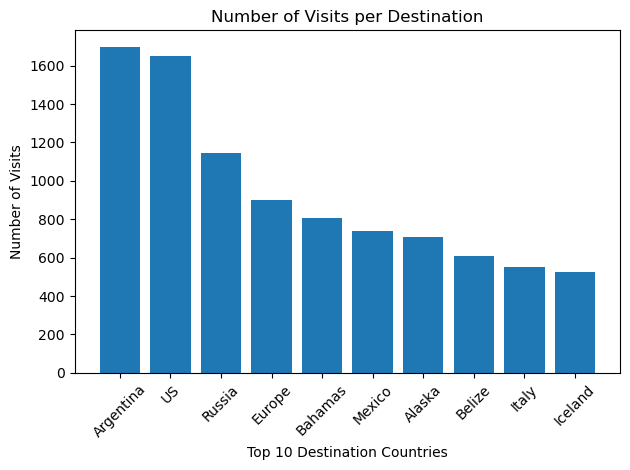

In [50]:
from matplotlib import pyplot as plt

times_visited = travel_data.destinationcountry.value_counts()
# print(times_visited)

plt.bar(x=times_visited.index[:10], height=times_visited.values[:10])

plt.xlabel("Top 10 Destination Countries")
plt.ylabel("Number of Visits")
plt.title("Number of Visits per Destination")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Argentina and the US are the most visited countries. Do they also generate the most commsions?

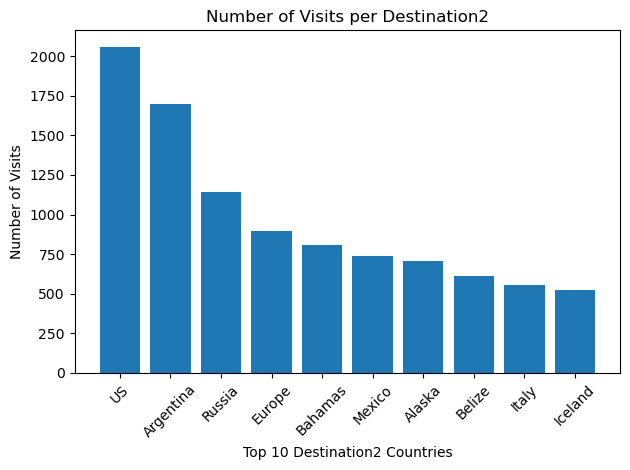

In [51]:
times_visited2 = travel_data.destinationcountry2.value_counts()
# print(times_visited2)

plt.bar(x=times_visited2.index[:10], height=times_visited2.values[:10])

plt.xlabel("Top 10 Destination2 Countries")
plt.ylabel("Number of Visits")
plt.title("Number of Visits per Destination2")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

This shows the second set of destinations is almost the same as the first set. We will focus on the first set. 

(array([1.4279e+04, 6.5100e+02, 8.2700e+02, 3.0400e+02, 2.3700e+02,
        7.9000e+01, 8.1000e+01, 7.8000e+01, 1.9000e+01, 2.9000e+01,
        5.0000e+00, 1.4000e+01, 4.0000e+00, 1.1000e+01, 1.4000e+01]),
 array([ 1.        ,  2.13333333,  3.26666667,  4.4       ,  5.53333333,
         6.66666667,  7.8       ,  8.93333333, 10.06666667, 11.2       ,
        12.33333333, 13.46666667, 14.6       , 15.73333333, 16.86666667,
        18.        ]),
 <BarContainer object of 15 artists>)

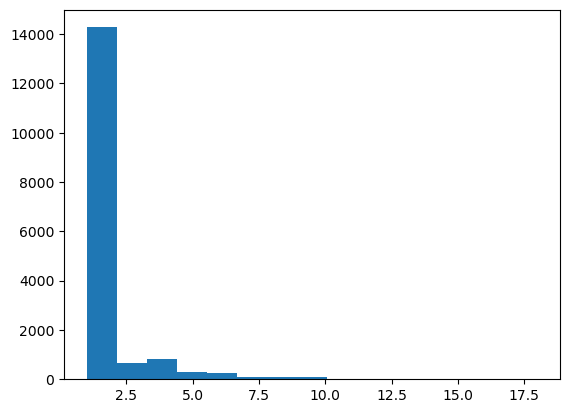

In [55]:
plt.hist(travel_data.groupsize, bins = 15)

This suggests that the travel agency mainly deals with small groups (1-2 people). Obviously a bigger group generates more commision. 

(array([3.000e+00, 4.290e+02, 3.519e+03, 5.660e+03, 5.353e+03, 5.260e+02,
        2.550e+02, 4.800e+01, 1.600e+01, 1.100e+01, 6.000e+00, 6.000e+00,
        1.000e+00, 1.000e+00, 3.000e+00, 0.000e+00, 0.000e+00, 1.000e+00,
        0.000e+00, 1.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 1.000e+00, 0.000e+00, 0.000e+00, 1.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 1.000e+00]),
 array([-0.07582938, -0.01567176,  0.04448587,  0.10464349,  0.16480112,
         0.22495874,  0.28511637,  0.34527399,  0.40543162,  0.46558924,
         0.52574687,  0.58590449,  0.64606212,  0.70621974,  0.76637737,
         0.82653499,  0.88669262,  0.94685025,  1.00700787,  1.0671655 ,
         1.12732312,  1.18748075,  1.24763837,  1.307796  ,  1.36795362,
         1.42811125,  1.48826887,  1.5484265 ,  1.60858412,  1.66874175,
         1.72889937,  1.789057  ,  1.84921462,  1.90937225,  1.96952987,
         2.0296875 ]),
 <BarContainer object of 35 art

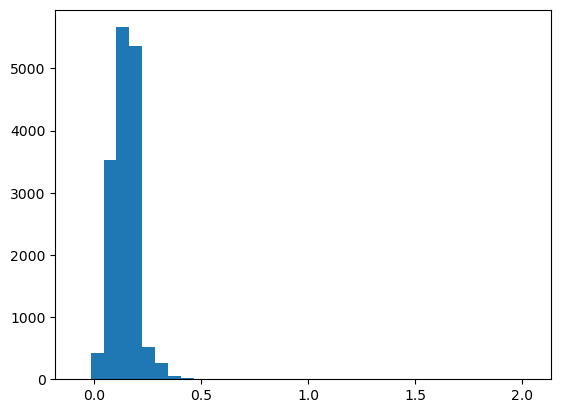

In [56]:
plt.hist(travel_data.profit_margin, bins = 35)

This shows the profit marginb is skewed a bit to the right. Which is good, since the median pofit margin is higher than the mean profit margin. 

In [8]:
# comm_by_k = travel_data.anticipatedcommission_total / 1000
# plt.hist2d(travel_data.groupsize, travel_data.comm_binned)
# print(travel_data.comm_binned.head(10))
counts = travel_data.comm_binned.value_counts()
# print(counts)
# print(travel_data.anticipatedcommission_total.min())
print(travel_data.shape)
# print(travel_data.countna())
null_blank_cols = travel_data.columns[travel_data.isna().any() | (travel_data.eq('').any())]
print(null_blank_cols)
null_profit = travel_data[travel_data.profit_margin.isna()]
print(null_profit.shape)
print(null_profit.head(10))

(16632, 17)
Index(['profit_margin', 'comm_binned'], dtype='object')
(790, 17)
      clientid     bkgref  Trip ID       destination destinationcountry  \
9       100651  B10-22631      808        Europe FIT             Europe   
29      100651  B17-44456      830            France             France   
65   01106KAT1  B10-23915      104    Canada Fishing             Canada   
66   01106KAT1  B11-26732      150    Alaska Fishing             Alaska   
115  01890DAR1  B18-47973      210  Grand Slam Lodge             Mexico   
152  01944AND1  B16-41605      516        Cordoba WS          Argentina   
169  01945NUT1  B14-36101      370  ARG Misc Fishing          Argentina   
223  02114WIC3  B21-55549      800     United States                 US   
314  02493JUP1  B10-23978      810          Asia FIT               Asia   
360  02650GOU2  B10-23804      104    Canada Fishing             Canada   

    destinationcountry2 category date_of_trip_from date_of_trip_to  year  \
9                Eur

In [19]:
travel_data.columns

Index(['clientid', 'bkgref', 'Trip ID', 'destination', 'destinationcountry',
       'destinationcountry2', 'category', 'date_of_trip_from',
       'date_of_trip_to', 'year', 'month', 'bkgsource', 'landsalecost_total',
       'anticipatedcommission_total', 'groupsize', 'profit_margin',
       'comm_binned'],
      dtype='object')

(array([2825., 1300., 1272., 1848., 1937., 1786., 1656., 1585.,  951.,
        1472.]),
 array([ 1. ,  2.1,  3.2,  4.3,  5.4,  6.5,  7.6,  8.7,  9.8, 10.9, 12. ]),
 <BarContainer object of 10 artists>)

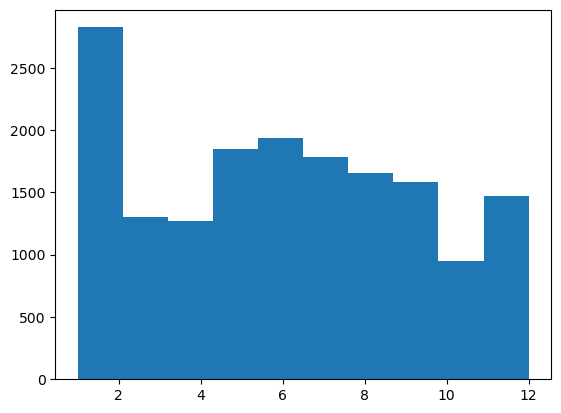

In [21]:
plt.hist(travel_data.month)

The highest number of trips is taken in Jan. with the biggest drop in sales being in october. 

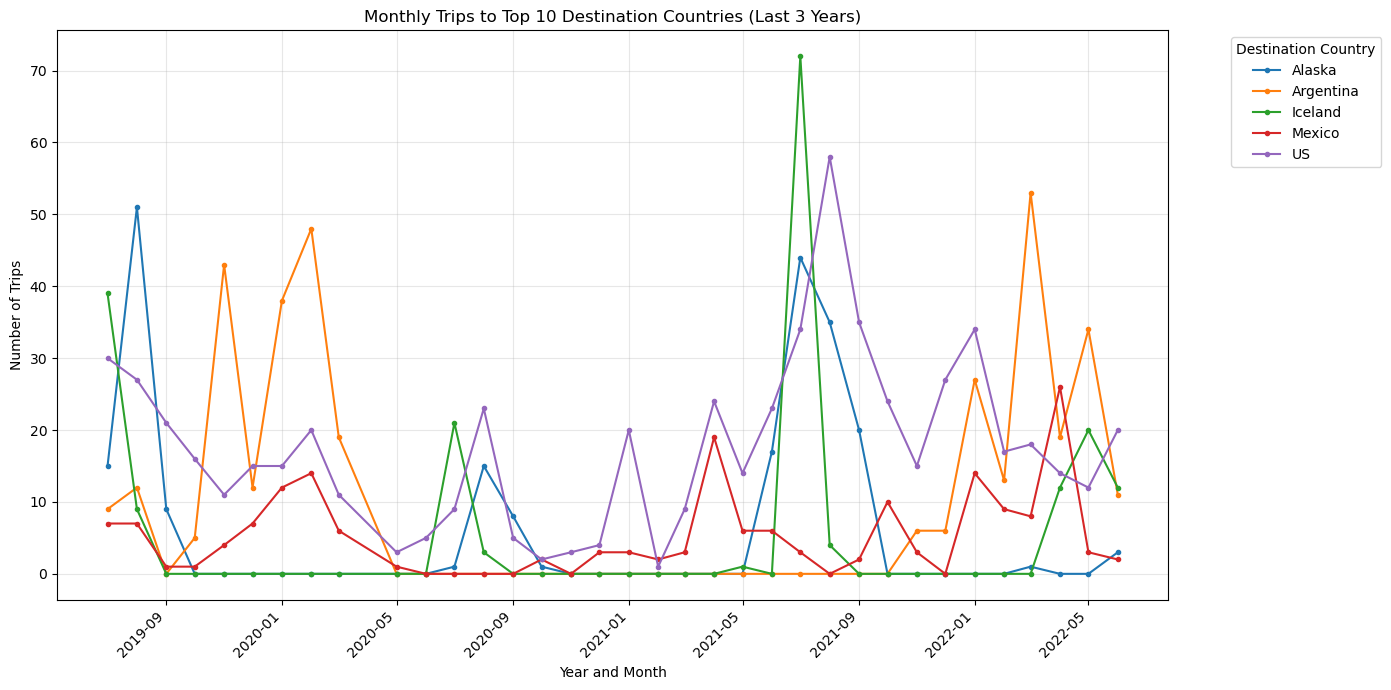

In [33]:

import pandas as pd
import matplotlib.pyplot as plt

# Create a date column from year and month
travel_data['date'] = pd.to_datetime(
    travel_data['year'].astype(str) + '-' +
    travel_data['month'].astype(str),
    format='%Y-%m'
)

# Find the latest date in the dataset
latest_date = travel_data['date'].max()

# Filter to the last 3 years (36 months)
start_date = latest_date - pd.DateOffset(years=3)

recent_data = travel_data[
    (travel_data['date'] > start_date) &
    (travel_data['date'] <= latest_date)
].copy()

# Find the top 10 destination countries within this period
top_5 = recent_data['destinationcountry'].value_counts().head(5).index

# Filter to the top 10 countries
top_data = recent_data[
    recent_data['destinationcountry'].isin(top_5)
]

# Count trips per month for each country
monthly_trips = (
    top_data.groupby(['date', 'destinationcountry'])
    .size()
    .unstack(fill_value=0)
)

# Plot the time series
monthly_trips.plot(figsize=(14, 7), marker='o', markersize=3)

plt.xlabel('Year and Month')
plt.ylabel('Number of Trips')
plt.title('Monthly Trips to Top 10 Destination Countries (Last 3 Years)')
plt.legend(
    title='Destination Country',
    bbox_to_anchor=(1.05, 1),
    loc='upper left'
)
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

This shows a large spike in customers travelling to iceland and US and Alaska in September. This trend is seen in the last 3 years consistently (with Covid in 2020 making a significant impact. )

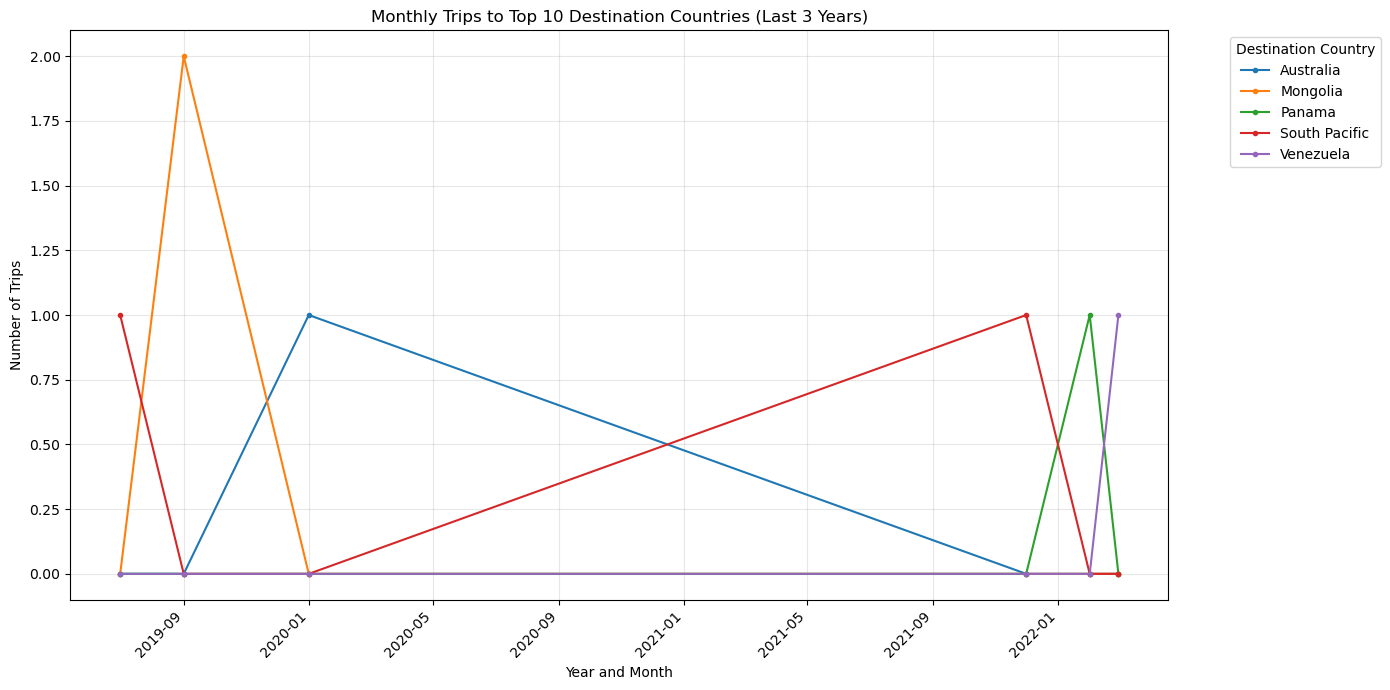

In [30]:
# Create a date column from year and month
travel_data['date'] = pd.to_datetime(
    travel_data['year'].astype(str) + '-' +
    travel_data['month'].astype(str),
    format='%Y-%m'
)

# Find the latest date in the dataset
latest_date = travel_data['date'].max()

# Filter to the last 3 years (36 months)
start_date = latest_date - pd.DateOffset(years=3)

recent_data = travel_data[
    (travel_data['date'] > start_date) &
    (travel_data['date'] <= latest_date)
].copy()

# Find the top 10 destination countries within this period
bottom_5 = recent_data['destinationcountry'].value_counts().tail(5).index

# Filter to the top 10 countries
top_data = recent_data[
    recent_data['destinationcountry'].isin(bottom_5)
]

# Count trips per month for each country
monthly_trips = (
    top_data.groupby(['date', 'destinationcountry'])
    .size()
    .unstack(fill_value=0)
)

# Plot the time series
monthly_trips.plot(figsize=(14, 7), marker='o', markersize=3)

plt.xlabel('Year and Month')
plt.ylabel('Number of Trips')
plt.title('Monthly Trips to Top 10 Destination Countries (Last 3 Years)')
plt.legend(
    title='Destination Country',
    bbox_to_anchor=(1.05, 1),
    loc='upper left'
)
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Austrailia has been consitently declining over the last 3 years, maybe take that destination off so they can focus on more profitable destinations?

In [36]:
lost_profit = travel_data[travel_data['anticipatedcommission_total'] < 0]
low_profit = travel_data[travel_data['anticipatedcommission_total'] < travel_data["anticipatedcommission_total"].mean()]
print(lost_profit.shape)
print(low_profit.shape)
high_profit = travel_data[travel_data['anticipatedcommission_total'] > travel_data["anticipatedcommission_total"].mean()]
print(lost_profit)
print(travel_data[travel_data['destination'] == "Iceland Trout"].size)

(3, 18)
(11528, 18)
        clientid     bkgref  Trip ID    destination destinationcountry  \
4074    12-53626  B16-42376      305  Iceland Trout            Iceland   
4078    12-53627  B16-42377      305  Iceland Trout            Iceland   
12634  44256BRA1  B16-42375      305  Iceland Trout            Iceland   

      destinationcountry2 category date_of_trip_from date_of_trip_to  year  \
4074              Iceland       FW          6/8/2017       6/14/2017  2017   
4078              Iceland       FW          6/8/2017       6/14/2017  2017   
12634             Iceland       FW          6/8/2017       6/16/2017  2017   

       month      bkgsource  landsalecost_total  anticipatedcommission_total  \
4074       6  Repeat Client              5275.0                       -400.0   
4078       6  Repeat Client              5275.0                       -400.0   
12634      6  Repeat Client              5275.0                       -400.0   

       groupsize  profit_margin comm_binned      

Looks like the only time the agency lost money was going to Iceland Trout, but that is an outlier since iceland Trout has many travellers. 

In [40]:
print(low_profit["bkgsource"].value_counts())
high_profit["bkgsource"].value_counts()

bkgsource
Repeat Client        6262
Company referral     1386
Friend               1377
UK                   1295
Agent/Outfitter       618
Web/Internet/Mail     484
Organizations          47
Unknown                17
Magazine               16
Frontiers, Ltd.        14
Trade Shows             7
Internet Chat           5
Name: count, dtype: int64


bkgsource
Repeat Client        2927
UK                    821
Company referral      556
Friend                492
Web/Internet/Mail     152
Agent/Outfitter       110
Frontiers, Ltd.        23
Unknown                 7
Magazine                7
Trade Shows             6
Organizations           3
Name: count, dtype: int64

Most of the clients come from Repeat Clients. However organizations is much more likely to have a low profit and so is Internet chat. These areas should not get marketing funding.

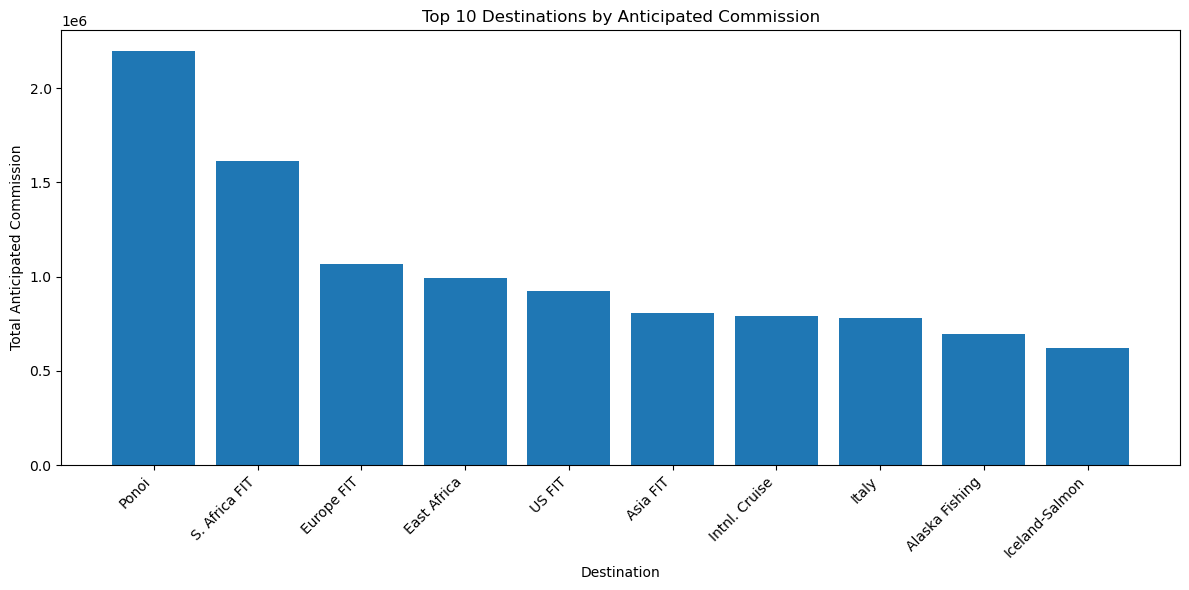

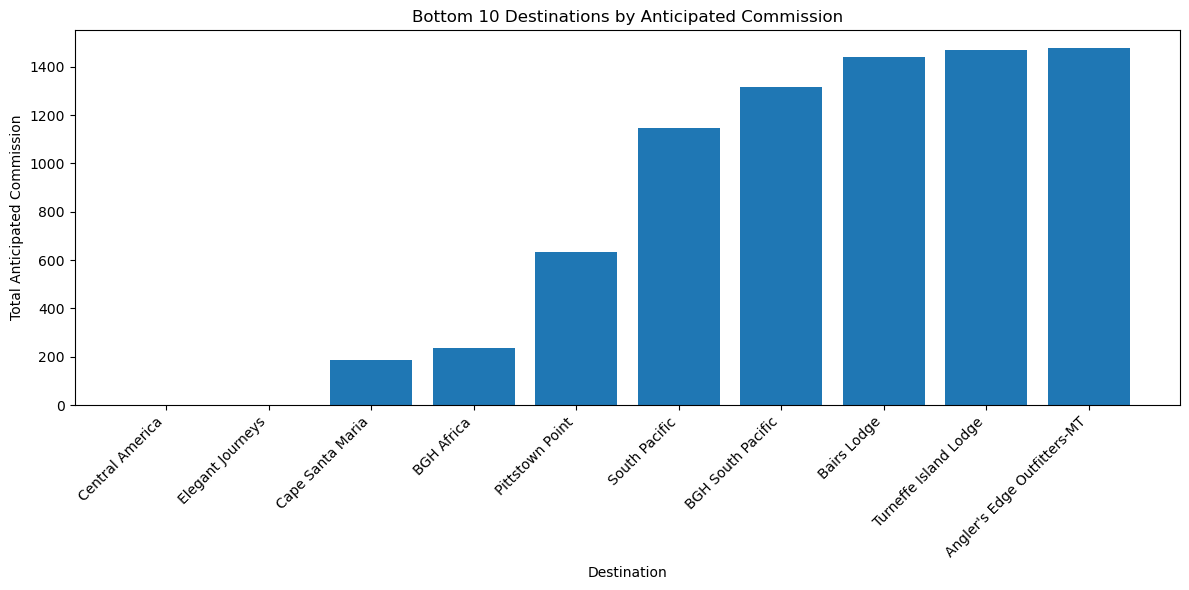

In [42]:

import matplotlib.pyplot as plt

# Calculate total anticipated commission per destination
commission_by_destination = (
    travel_data.groupby('destination')['anticipatedcommission_total']
    .sum()
    .sort_values(ascending=False)
)

# Get top 10 and bottom 10 destinations
top_10 = commission_by_destination.head(10)
bottom_10 = commission_by_destination.tail(10).sort_values()

# Graph 1: Top 10 destinations
plt.figure(figsize=(12, 6))
plt.bar(top_10.index, top_10.values)

plt.xlabel('Destination')
plt.ylabel('Total Anticipated Commission')
plt.title('Top 10 Destinations by Anticipated Commission')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


# Graph 2: Bottom 10 destinations
plt.figure(figsize=(12, 6))
plt.bar(bottom_10.index, bottom_10.values)

plt.xlabel('Destination')
plt.ylabel('Total Anticipated Commission')
plt.title('Bottom 10 Destinations by Anticipated Commission')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

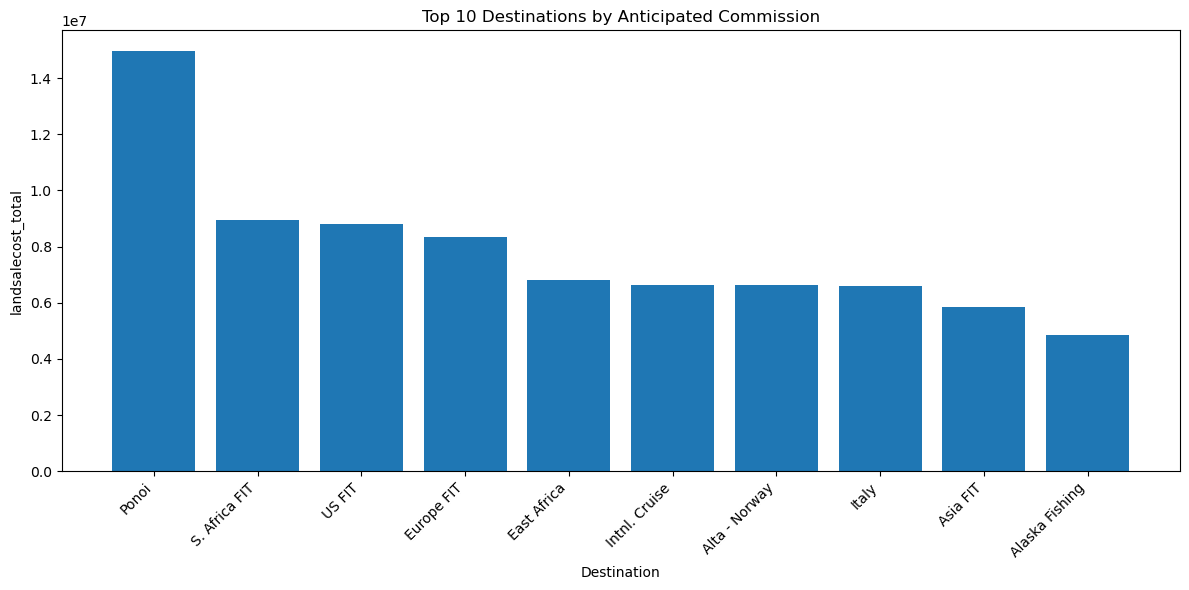

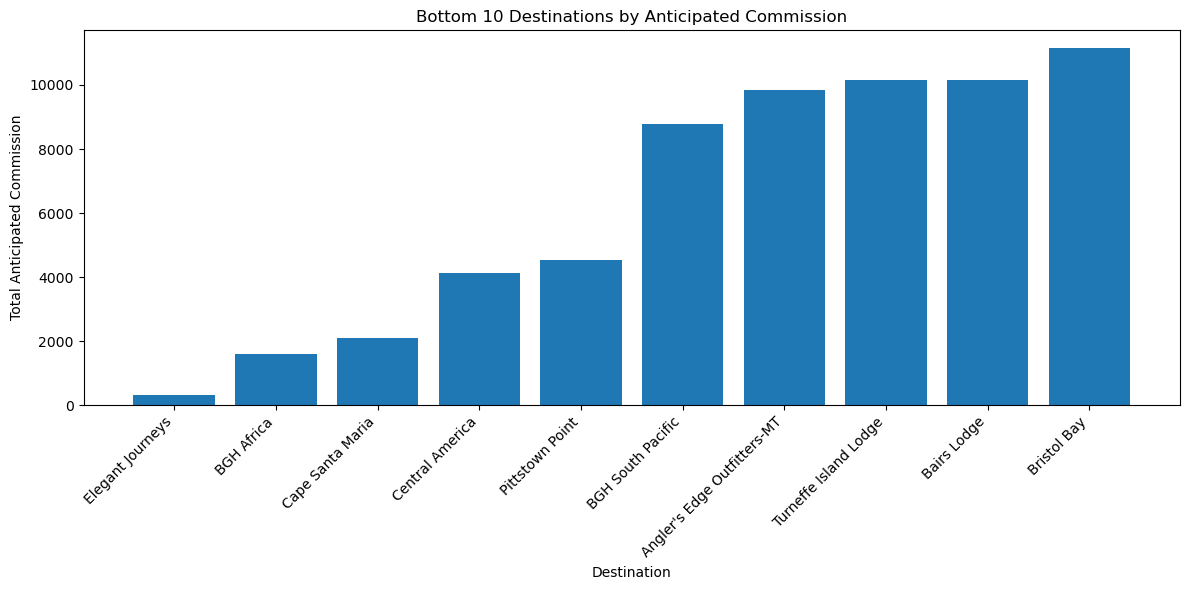

In [44]:

import matplotlib.pyplot as plt

# Calculate total anticipated commission per destination
commission_by_destination = (
    travel_data.groupby('destination')['landsalecost_total']
    .sum()
    .sort_values(ascending=False)
)

# Get top 10 and bottom 10 destinations
top_10 = commission_by_destination.head(10)
bottom_10 = commission_by_destination.tail(10).sort_values()

# Graph 1: Top 10 destinations
plt.figure(figsize=(12, 6))
plt.bar(top_10.index, top_10.values)

plt.xlabel('Destination')
plt.ylabel('landsalecost_total')
plt.title('Top 10 Destinations by Anticipated Commission')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


# Graph 2: Bottom 10 destinations
plt.figure(figsize=(12, 6))
plt.bar(bottom_10.index, bottom_10.values)

plt.xlabel('Destination')
plt.ylabel('Total Anticipated Commission')
plt.title('Bottom 10 Destinations by Anticipated Commission')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

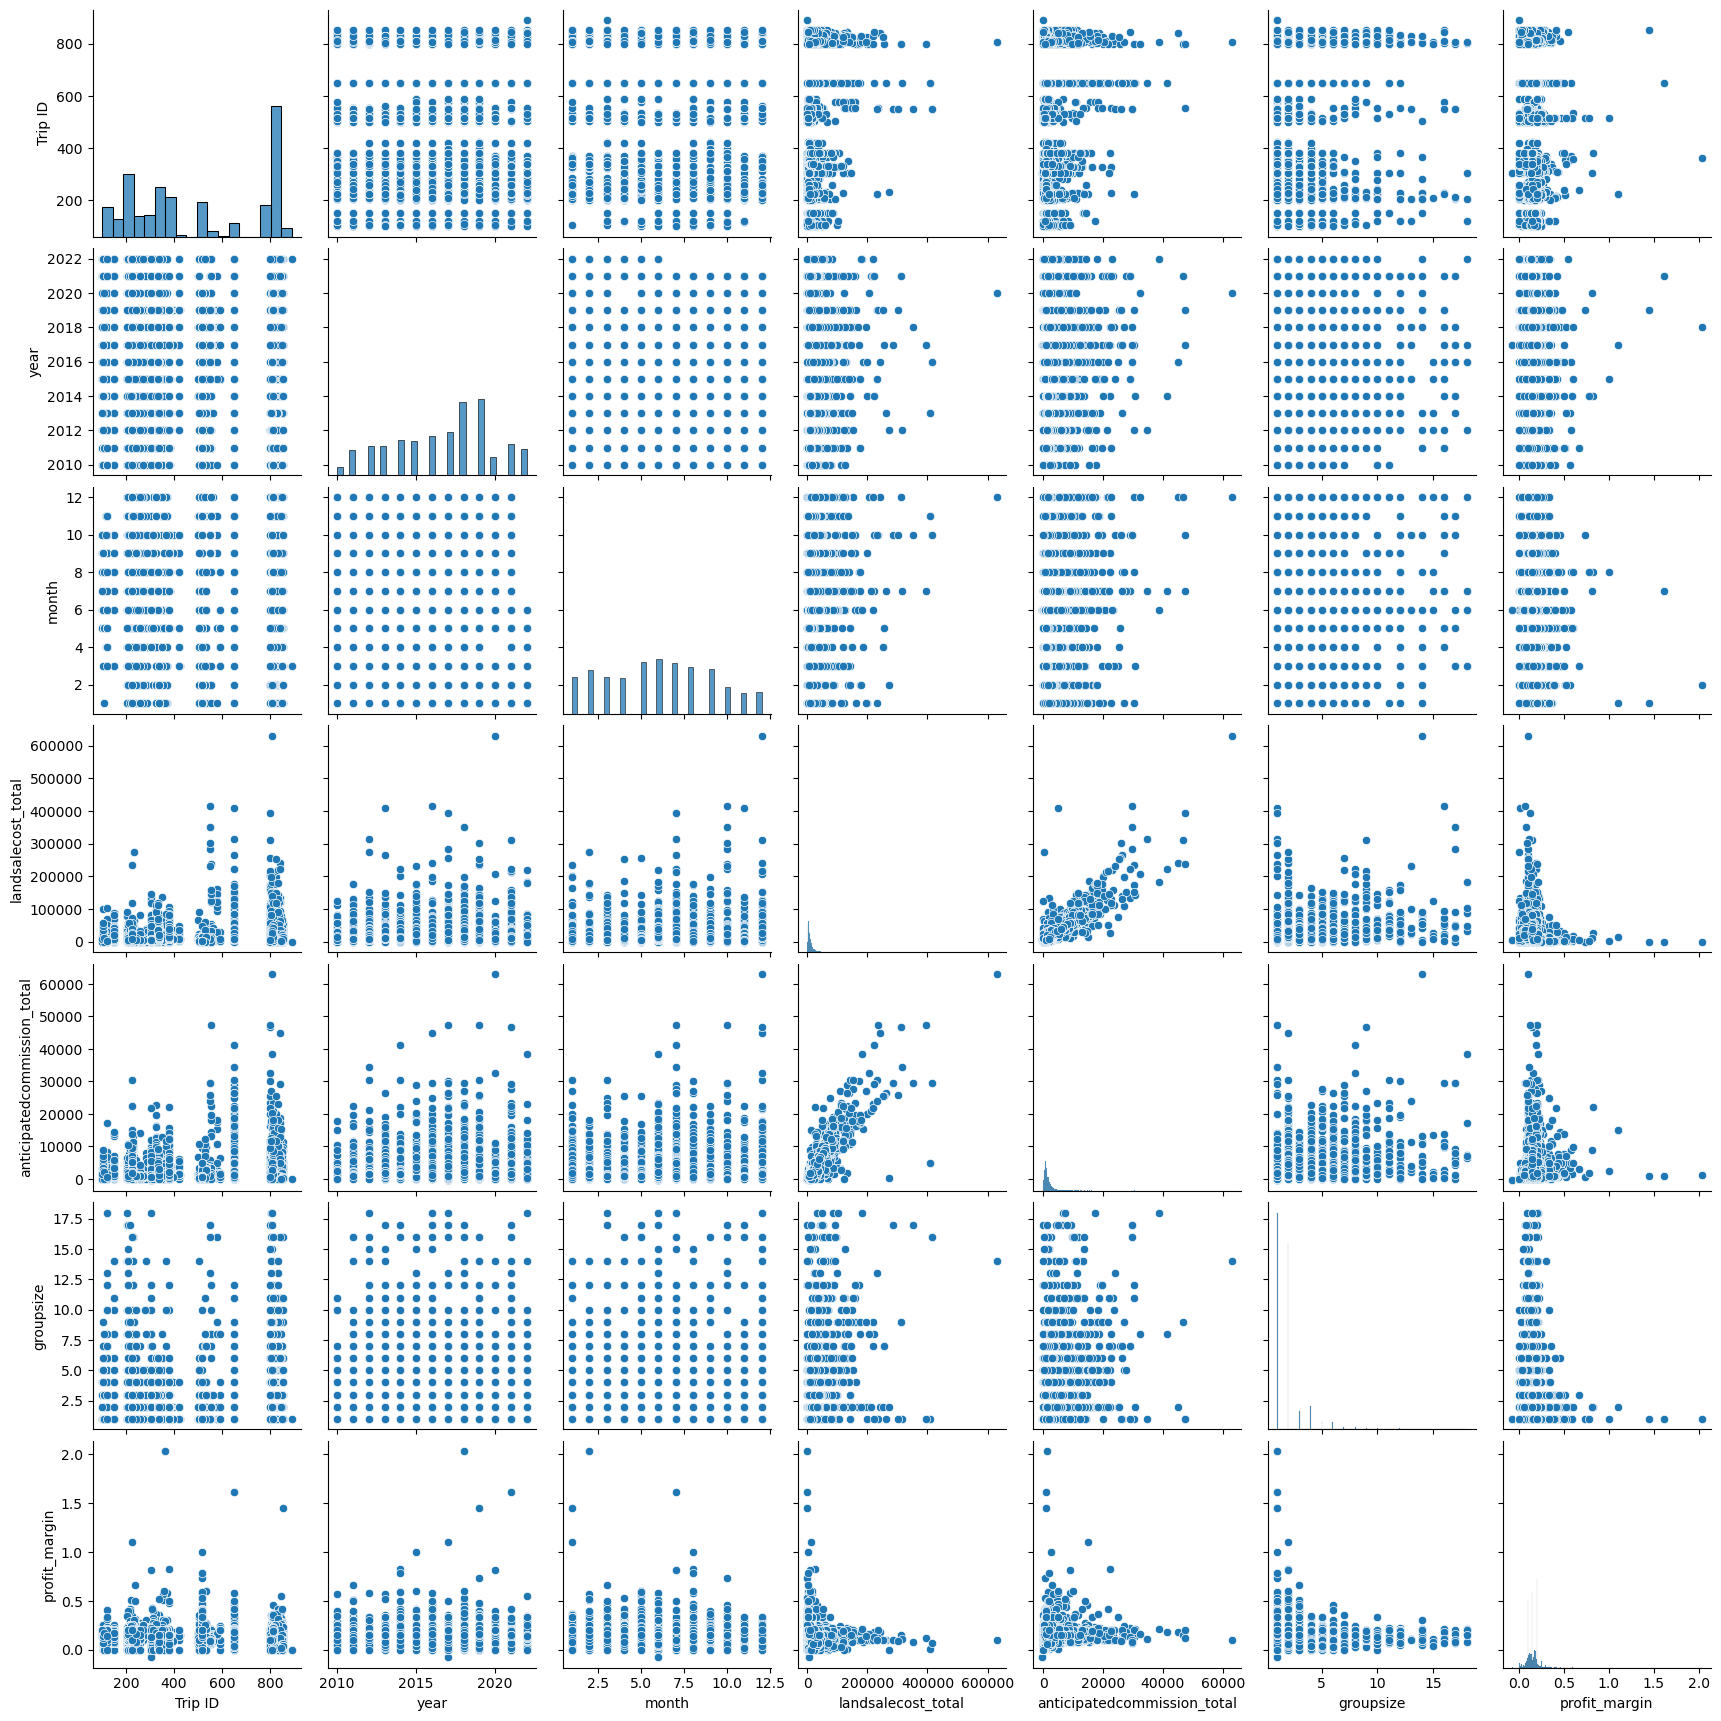

In [45]:
import seaborn as sb
sb.pairplot(travel_data)

The land cost has a positive direct correlation with anticipated commision. 

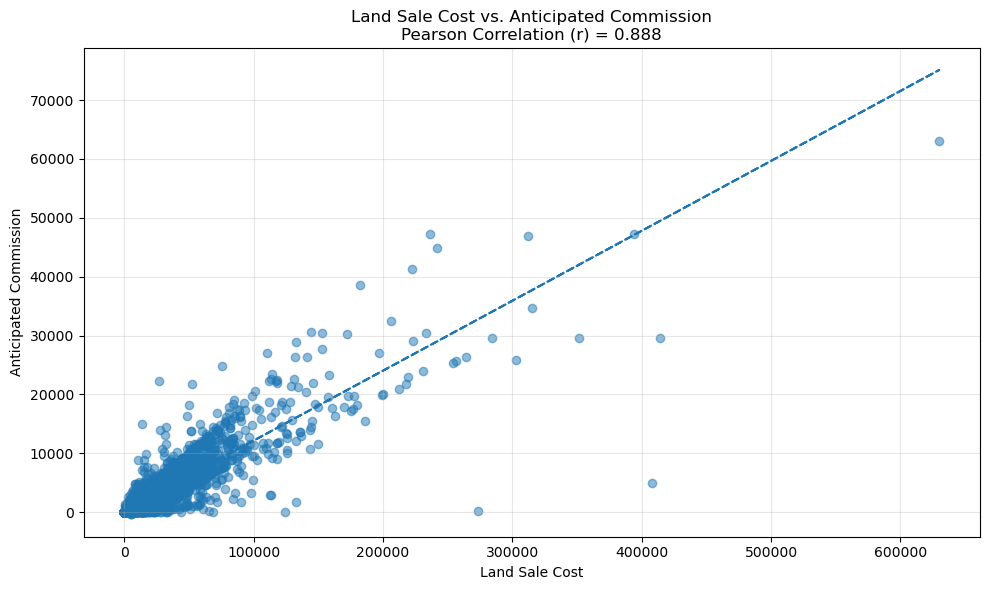

Pearson correlation coefficient: 0.888
P-value: 0


In [46]:

import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# Select the two columns and remove missing or infinite values
data = travel_data[
    ['landsalecost_total', 'anticipatedcommission_total']
].copy()

data = data.replace([float('inf'), float('-inf')], float('nan')).dropna()

# Calculate Pearson correlation coefficient
correlation, p_value = pearsonr(
    data['landsalecost_total'],
    data['anticipatedcommission_total']
)

# Create scatter plot
plt.figure(figsize=(10, 6))

plt.scatter(
    data['landsalecost_total'],
    data['anticipatedcommission_total'],
    alpha=0.5
)

plt.xlabel('Land Sale Cost')
plt.ylabel('Anticipated Commission')
plt.title(
    f'Land Sale Cost vs. Anticipated Commission\n'
    f'Pearson Correlation (r) = {correlation:.3f}'
)

# Add a trend line
plt.plot(
    data['landsalecost_total'],
    __import__('numpy').poly1d(
        __import__('numpy').polyfit(
            data['landsalecost_total'],
            data['anticipatedcommission_total'],
            1
        )
    )(data['landsalecost_total']),
    linestyle='--'
)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f'Pearson correlation coefficient: {correlation:.3f}')
print(f'P-value: {p_value:.4g}')


This could imply that a higher land cost would lead to higher commision. More investigation is needed. 

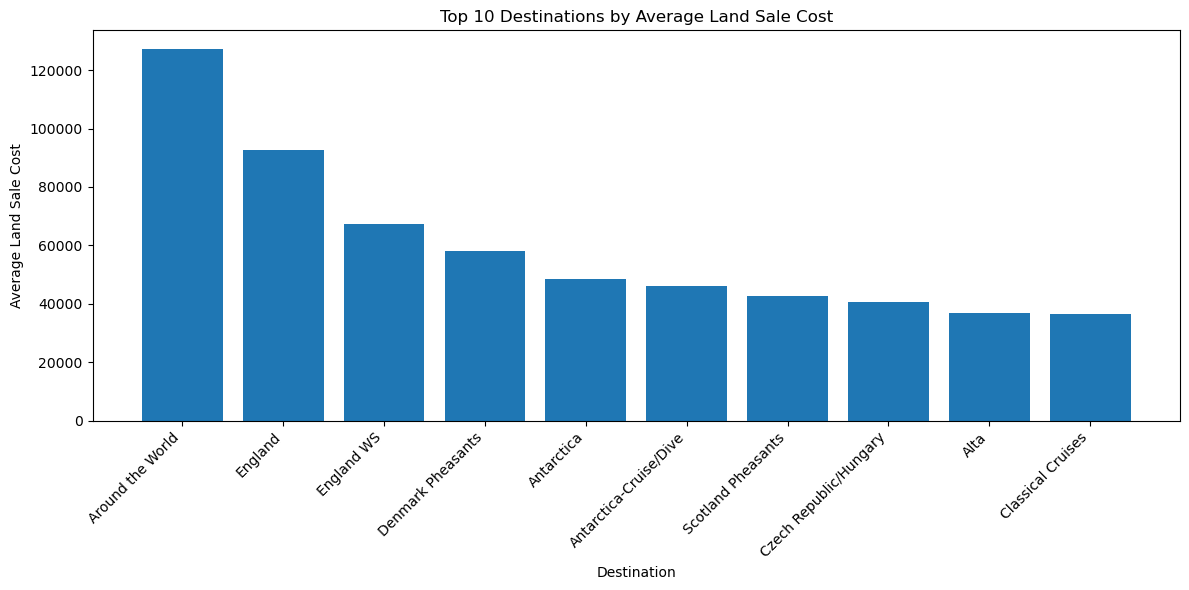

In [47]:
import matplotlib.pyplot as plt

# Calculate average land sale cost for each destination
avg_cost = (
    travel_data.groupby('destination')['landsalecost_total']
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

# Plot the top 10 destinations
plt.figure(figsize=(12, 6))
plt.bar(avg_cost.index, avg_cost.values)

plt.xlabel('Destination')
plt.ylabel('Average Land Sale Cost')
plt.title('Top 10 Destinations by Average Land Sale Cost')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

The destinations with high land sale cost are not the same set as the destinations with the hiest revenue. 

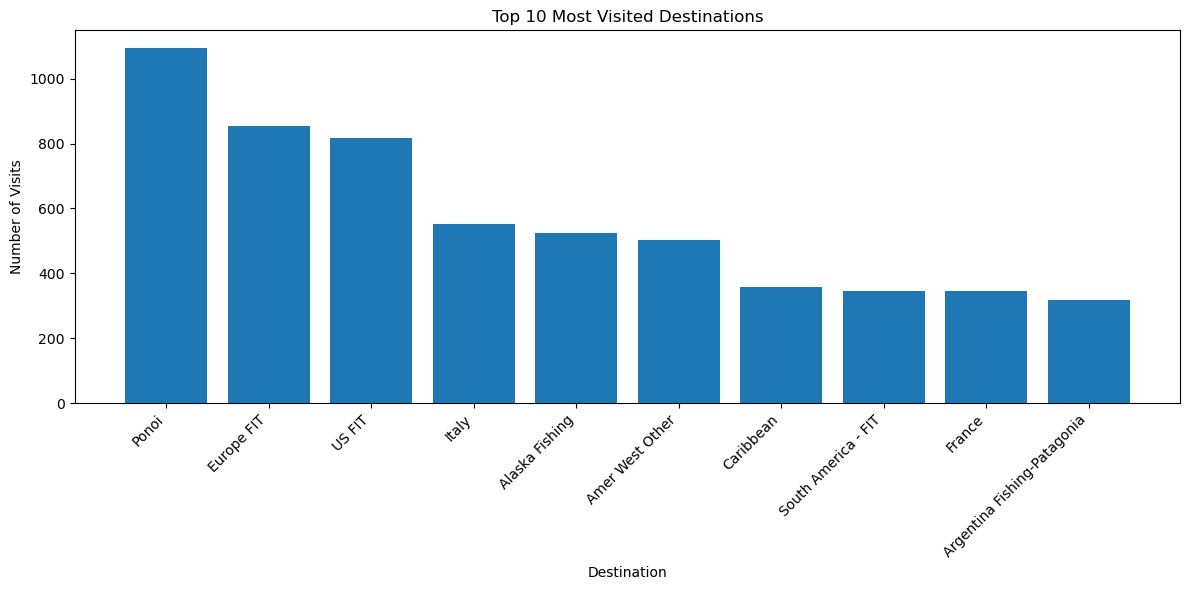

In [48]:
import matplotlib.pyplot as plt

# Count visits to each destination and select the top 10
top_10 = travel_data['destination'].value_counts().head(10)

# Create the bar chart
plt.figure(figsize=(12, 6))
plt.bar(top_10.index, top_10.values)

plt.xlabel('Destination')
plt.ylabel('Number of Visits')
plt.title('Top 10 Most Visited Destinations')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

The destinations with the highest visitaion are similar to the destinations with the most commsions. This implies that there is no need to spend more on pricy land. The company should buy more land in the most commision driving areas, since they are popular. 

In [61]:
travel_data.category.value_counts()

category
FIT    6048
FO     3262
SW     3021
FW     2329
WS     1457
AFR     468
BGH      47
Name: count, dtype: int64

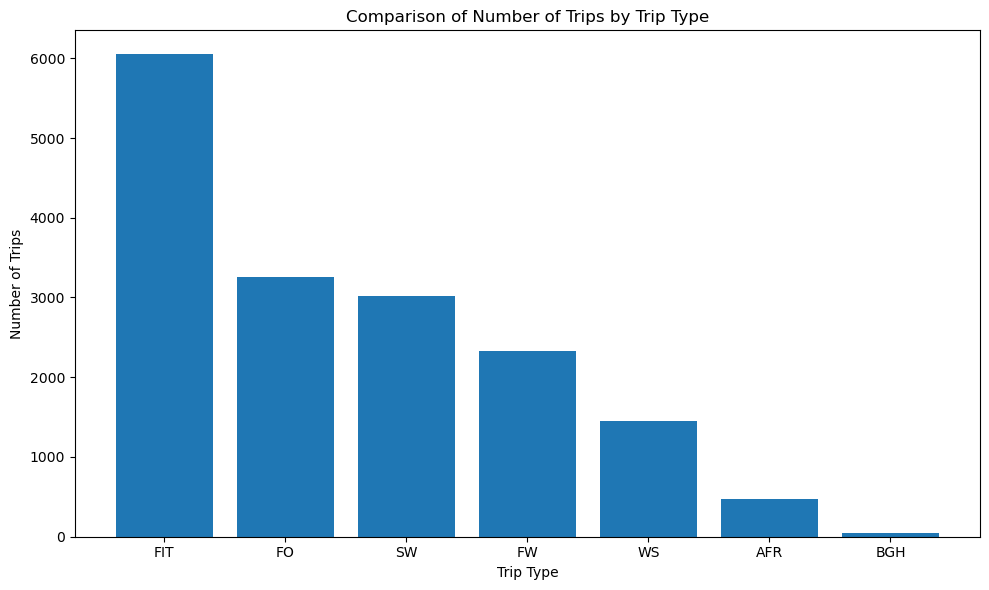

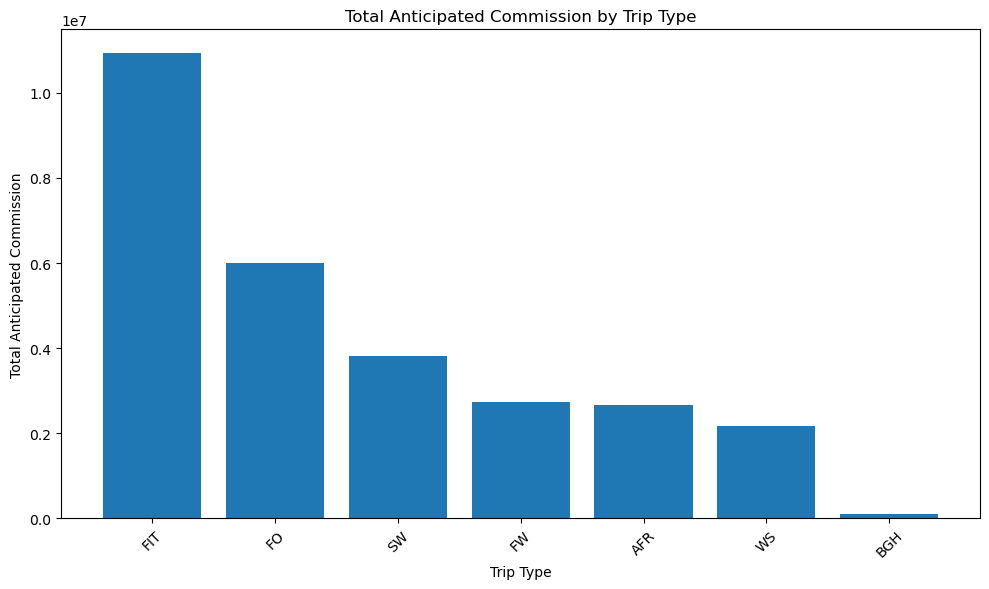

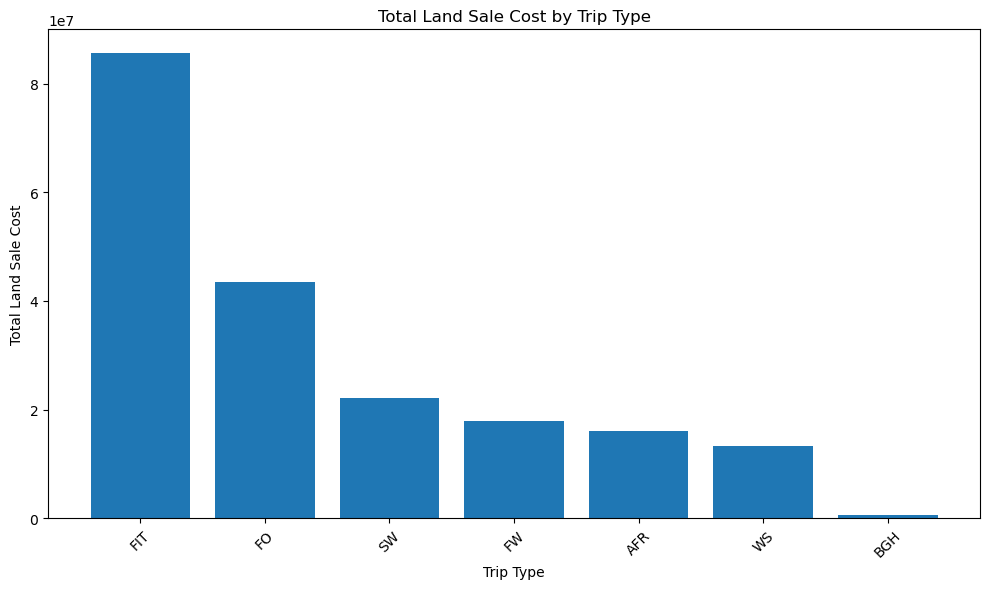

In [71]:
import matplotlib.pyplot as plt
import pandas as pd

# Define trip type columns
categories = [
    "FIT", "FO", "SW","FW","WS","AFR","BGH"
]


# 1. Number of trips by trip type
trip_counts = travel_data["category"].value_counts()

plt.figure(figsize=(10, 6))
plt.bar(trip_counts.index, trip_counts.values)
plt.xlabel('Trip Type')
plt.ylabel('Number of Trips')
plt.title('Comparison of Number of Trips by Trip Type')
plt.tight_layout()
plt.show()

# Total anticipated commission by trip type
commission = (
    travel_data.groupby('category')['anticipatedcommission_total']
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))
plt.bar(commission.index, commission.values)

plt.xlabel('Trip Type')
plt.ylabel('Total Anticipated Commission')
plt.title('Total Anticipated Commission by Trip Type')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Total land sale cost by trip type
land_cost = (
    travel_data.groupby('category')['landsalecost_total']
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))
plt.bar(land_cost.index, land_cost.values)

plt.xlabel('Trip Type')
plt.ylabel('Total Land Sale Cost')
plt.title('Total Land Sale Cost by Trip Type')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

This shows the afr type of trip makes more comsion per trip than WS. Focus more on AFR trips than WS. 

# K means cluster analysis

Number of trips included: 15842
Variables used: ['landsalecost_total', 'anticipatedcommission_total', 'groupsize', 'profit_margin']


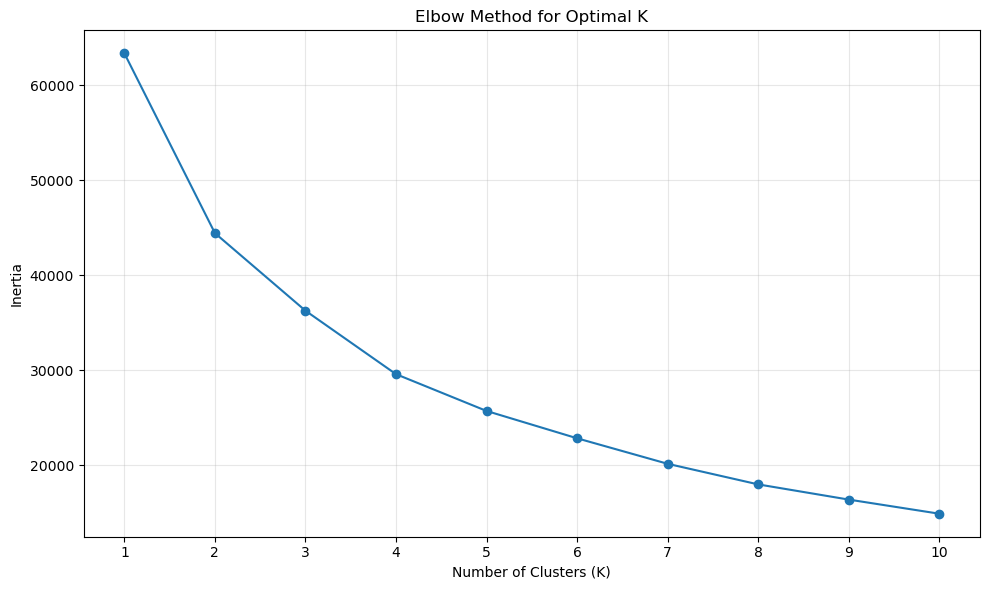

    landsalecost_total  anticipatedcommission_total  groupsize  profit_margin  \
0               4550.0                       455.00          1       0.100000   
1               7260.0                      1012.52          4       0.139466   
2              14598.5                      2300.00          4       0.157550   
3              14280.0                      2856.00          4       0.200000   
4               7615.0                       914.40          2       0.120079   
5               4500.0                       675.00          1       0.150000   
6               5630.0                      1894.00          1       0.336412   
7              24400.0                      4888.00          4       0.200328   
8              13664.0                      2440.00          2       0.178571   
10              3200.0                       320.00          2       0.100000   

    Cluster  
0         3  
1         3  
2         3  
3         0  
4         3  
5         0  
6         

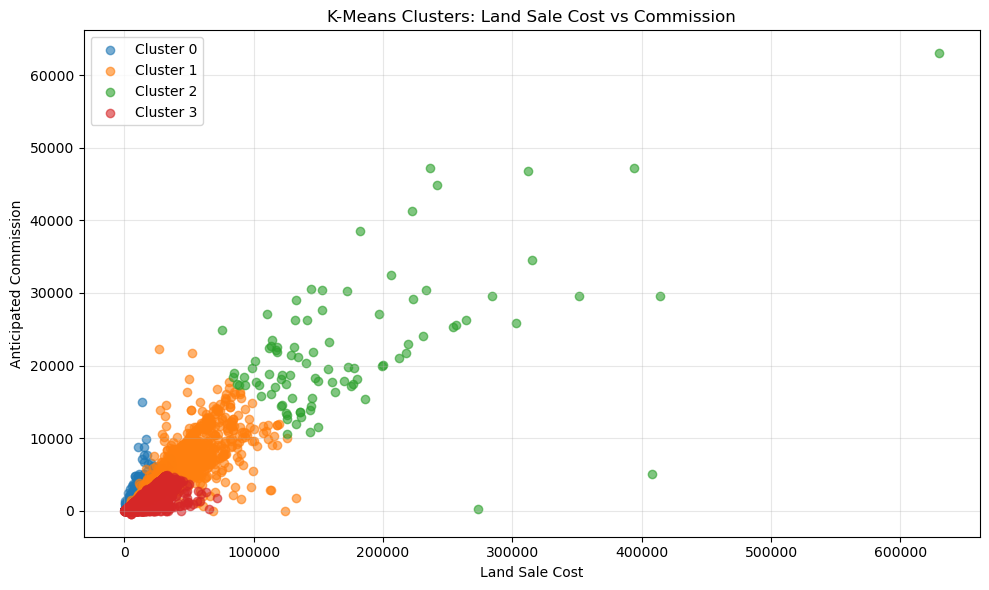

In [75]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Select numerical variables for clustering
features = [
    'landsalecost_total',
    'anticipatedcommission_total',
    'groupsize',
    'profit_margin'
]

# Convert selected columns to numeric
X = travel_data[features].copy()

for col in features:
    X[col] = pd.to_numeric(X[col], errors='coerce')

# Replace infinite values and remove rows with missing values
X = X.replace([np.inf, -np.inf], np.nan)
valid_rows = X.notna().all(axis=1)
X_clean = X.loc[valid_rows].copy()

# Standardize the variables
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_clean)

print("Number of trips included:", len(X_clean))
print("Variables used:", features)
# Calculate inertia for different numbers of clusters
inertia = []
k_values = range(1, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# Plot the elbow curve
plt.figure(figsize=(10, 6))
plt.plot(k_values, inertia, marker='o')

plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal K')
plt.xticks(k_values)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
# Fit K-means with 3 clusters
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(X_scaled)

# Add cluster labels to the original data
clustered_data = travel_data.loc[valid_rows].copy()
clustered_data['Cluster'] = cluster_labels

# Display the first rows
print(clustered_data[
    features + ['Cluster']
].head(10))
plt.figure(figsize=(10, 6))

for cluster in sorted(clustered_data['Cluster'].unique()):
    cluster_data = clustered_data[
        clustered_data['Cluster'] == cluster
    ]

    plt.scatter(
        cluster_data['landsalecost_total'],
        cluster_data['anticipatedcommission_total'],
        alpha=0.6,
        label=f'Cluster {cluster}'
    )

plt.xlabel('Land Sale Cost')
plt.ylabel('Anticipated Commission')
plt.title('K-Means Clusters: Land Sale Cost vs Commission')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [76]:
# Calculate average values for each cluster
cluster_summary = clustered_data.groupby('Cluster')[features].mean().round(2)

print("Average characteristics by cluster:")
print(cluster_summary)

# Count trips in each cluster
print("\nNumber of trips in each cluster:")
print(clustered_data['Cluster'].value_counts().sort_index())

Average characteristics by cluster:
         landsalecost_total  anticipatedcommission_total  groupsize  \
Cluster                                                               
0                   7844.51                      1468.66       1.38   
1                  41644.00                      5967.97       5.03   
2                 172976.61                     22129.35       6.55   
3                  10770.65                      1127.85       2.05   

         profit_margin  
Cluster                 
0                 0.19  
1                 0.15  
2                 0.14  
3                 0.10  

Number of trips in each cluster:
Cluster
0    8143
1    1206
2      94
3    6399
Name: count, dtype: int64


This shows the business has the greatest chance of losing money on groups of 5 people, and should encourage people to bump up to 6 people per tip. The greatest profit is found in the cluster of 6 people, however this is the lowest number of trips. If the business can incentivize groups to move from 5 to 6 people. there is a chance of profit. 